# Worker tracking and short-term movement prediction for danger-zone warnings

Mini-project 2. A YOLO detector finds workers in a construction-site video, and ByteTrack gives each worker a stable ID. The script estimates each worker's walking velocity, predicts their position a few seconds ahead with a constant-velocity model, and raises a three-level warning:

| Level | Rule |
| --- | --- |
| **STOP** | worker is inside the danger zone now |
| **WARN** | worker is predicted to enter the zone within 3 s |
| **INFORM** | worker is predicted to enter the zone within 5 s |

This mirrors the tiered warning idea in Wong et al. (2023) for tower-crane lifting. All positions and speeds are in **pixels**; converting them to metres needs camera calibration (mini-project 3).

**Before you start:** Settings > Accelerator > GPU, and Settings > Internet > On.

## 1. Setup

In [10]:
!pip install -q ultralytics lap
import ultralytics, cv2, glob, os, math, numpy as np, pandas as pd
from collections import defaultdict, deque
from ultralytics import YOLO
ultralytics.checks()

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 5642.4/8156.9 GB disk)


## 2. Choose the model and the video

**Model.** If you upload `best.pt` from your PPE project (Add Input > Upload), it is used. Otherwise the notebook falls back to the standard `yolo26n.pt`, which already detects people well.

**Video.** Download a short construction-site clip (10-60 s, people walking, a fixed camera is best) from a free stock site such as Pexels or Pixabay. Upload it with **Add Input > Upload > New dataset**. The cell below finds the first video automatically.

In [11]:
weights = sorted(glob.glob("/kaggle/input/**/best.pt", recursive=True) + glob.glob("best.pt"))
MODEL_PATH = weights[0] if weights else "yolo26n.pt"
model = YOLO(MODEL_PATH)
PERSON_IDS = [i for i, n in model.names.items() if n.lower() == "person"]
print("Model:", MODEL_PATH, "| person class id(s):", PERSON_IDS)

videos = sorted(sum([glob.glob(f"{d}/**/*.{e}", recursive=True)
                     for d in ["/kaggle/input", "."] for e in ["mp4", "mov", "avi", "MP4", "MOV"]], []))
videos = [v for v in videos if "/runs/" not in v and "tracked_" not in v]
assert videos, "No video found. Upload one with Add Input > Upload."
VIDEO = videos[0]
cap = cv2.VideoCapture(VIDEO)
FPS = cap.get(cv2.CAP_PROP_FPS) or 25
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
N_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, first_frame = cap.read()
cap.release()
print(f"Video: {VIDEO}\n{W}x{H} px, {FPS:.1f} fps, {N_FRAMES} frames ({N_FRAMES / FPS:.1f} s)")

Model: yolo26n.pt | person class id(s): [0]
Video: /kaggle/input/datasets/afzalsiraj88/construction-site-video/Safety Video.mp4
852x480 px, 30.0 fps, 1844 frames (61.5 s)


## 3. Draw the danger zone

The zone is a polygon given as **fractions of the image width and height** (0 = left/top, 1 = right/bottom), so it works for any video size. Imagine it as the area under a suspended load or around a machine.

Run the cell, look at the picture, and adjust `ZONE` until it covers a sensible area that some workers walk through.

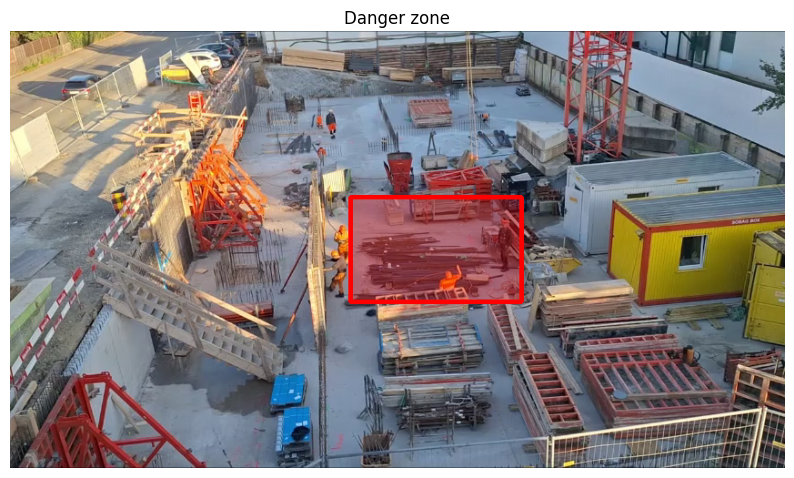

In [13]:
ZONE = [(0.44, 0.38), (0.66, 0.38), (0.66, 0.62), (0.44, 0.62)]   # crane load landing area   # edit me

ZONE_PX = np.array([(int(x * W), int(y * H)) for x, y in ZONE], np.int32)

def in_zone(pt):
    return cv2.pointPolygonTest(ZONE_PX, (float(pt[0]), float(pt[1])), False) >= 0

preview = first_frame.copy()
overlay = preview.copy()
cv2.fillPoly(overlay, [ZONE_PX], (0, 0, 255))
preview = cv2.addWeighted(overlay, 0.3, preview, 0.7, 0)
cv2.polylines(preview, [ZONE_PX], True, (0, 0, 255), 3)
cv2.imwrite("zone_preview.jpg", preview)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6)); plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title("Danger zone"); plt.show()

## 4. Warning settings

- A worker's position is the **bottom-centre of their box** (their feet), because that is where they stand on the ground.
- Velocity is the average movement over the last `VEL_WINDOW_S` seconds, which smooths out jitter in the boxes.
- The predicted path is checked every 0.25 s up to 5 s ahead. A path that crosses the zone triggers WARN or INFORM.

In [14]:
WARN_S = 3.0          # predicted entry within this time -> WARN
INFORM_S = 5.0        # predicted entry within this time -> INFORM
VEL_WINDOW_S = 0.5    # seconds of history used to estimate velocity
MIN_SPEED_PX_S = 15   # slower than this counts as standing still (box jitter)
CONF = 0.35
IMGSZ = 1280        # larger input helps with small, distant workers (try 640 if it is slow)

LEVELS = ["SAFE", "INFORM", "WARN", "STOP"]
COLOURS = {"SAFE": (80, 180, 80), "INFORM": (0, 200, 255), "WARN": (0, 128, 255), "STOP": (0, 0, 255)}

def assess(history):
    """history: deque of (t, x, y). Returns level, velocity (px/s), predicted point at WARN_S, time-to-entry."""
    t, x, y = history[-1]
    if in_zone((x, y)):
        return "STOP", (0.0, 0.0), (x, y), 0.0
    old = [h for h in history if t - h[0] >= VEL_WINDOW_S]
    t0, x0, y0 = old[-1] if old else history[0]
    dt = t - t0
    vx, vy = ((x - x0) / dt, (y - y0) / dt) if dt > 0 else (0.0, 0.0)
    if math.hypot(vx, vy) < MIN_SPEED_PX_S:
        return "SAFE", (vx, vy), (x, y), None
    for k in range(1, int(INFORM_S / 0.25) + 1):
        tau = k * 0.25
        if in_zone((x + vx * tau, y + vy * tau)):
            level = "WARN" if tau <= WARN_S else "INFORM"
            return level, (vx, vy), (x + vx * WARN_S, y + vy * WARN_S), tau
    return "SAFE", (vx, vy), (x + vx * WARN_S, y + vy * WARN_S), None

## 5. Track, predict and warn

This runs the detector and tracker on every frame, writes an annotated video, and logs every worker's position and warning level to a table.

In [15]:
os.makedirs("results", exist_ok=True)
OUT_VIDEO = "results/tracked_output.mp4"
writer = cv2.VideoWriter(OUT_VIDEO, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))

histories = defaultdict(lambda: deque(maxlen=int(FPS * 3)))
log = []
example_saved = False   # first frame with a WARN (shows the prediction arrow)
stop_saved = False

for i, r in enumerate(model.track(VIDEO, stream=True, persist=True, tracker="bytetrack.yaml",
                                  classes=PERSON_IDS, conf=CONF, imgsz=IMGSZ, verbose=False)):
    t = i / FPS
    frame = r.orig_img.copy()
    frame_levels = []
    if r.boxes.id is not None:
        for (x1, y1, x2, y2), tid in zip(r.boxes.xyxy.tolist(), r.boxes.id.int().tolist()):
            foot = ((x1 + x2) / 2, y2)
            histories[tid].append((t, *foot))
            level, (vx, vy), pred, tte = assess(histories[tid])
            frame_levels.append(level)
            log.append({"frame": i, "time_s": round(t, 3), "worker_id": tid,
                        "x_px": round(foot[0], 1), "y_px": round(foot[1], 1),
                        "vx_px_s": round(vx, 1), "vy_px_s": round(vy, 1),
                        "level": level, "time_to_entry_s": tte})
            c = COLOURS[level]
            cv2.rectangle(frame, (int(x1), int(y1)), (int(x2), int(y2)), c, 2)
            cv2.putText(frame, f"#{tid} {level}", (int(x1), int(y1) - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, c, 2)
            if level != "STOP" and math.hypot(vx, vy) >= MIN_SPEED_PX_S:
                cv2.arrowedLine(frame, (int(foot[0]), int(foot[1])), (int(pred[0]), int(pred[1])), c, 2, tipLength=0.2)
    worst = max(frame_levels, key=LEVELS.index) if frame_levels else "SAFE"
    overlay = frame.copy()
    cv2.fillPoly(overlay, [ZONE_PX], COLOURS[worst])
    frame = cv2.addWeighted(overlay, 0.25, frame, 0.75, 0)
    cv2.polylines(frame, [ZONE_PX], True, COLOURS[worst], 3)
    cv2.rectangle(frame, (0, 0), (W, 36), (30, 30, 30), -1)
    cv2.putText(frame, f"t = {t:5.1f} s   zone status: {worst}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, COLOURS[worst], 2)
    writer.write(frame)
    if not example_saved and "WARN" in frame_levels:
        cv2.imwrite("results/example_warning_frame.jpg", frame); example_saved = True
    if not stop_saved and worst == "STOP":
        cv2.imwrite("results/example_stop_frame.jpg", frame); stop_saved = True

writer.release()
df = pd.DataFrame(log)
df.to_csv("results/track_log.csv", index=False)
print(f"Processed {i + 1} frames. Video saved to {OUT_VIDEO}")
print(f"Workers tracked: {df.worker_id.nunique() if len(df) else 0}")

Processed 1844 frames. Video saved to results/tracked_output.mp4
Workers tracked: 41


## 6. Results

**Warning lead time** is the key number. For every worker who actually entered the zone, how many seconds before entering did they first get a WARN or INFORM? A longer lead time means more time to react.

Only workers who were **seen outside the zone first** count as entries. If a worker is first detected already inside the zone (because they were there when the video started, or the tracker lost and re-found them), their entry was not observed, so no lead time can be measured.

In [16]:
summary = []
for tid, g in df.groupby("worker_id"):
    g = g.sort_values("time_s")
    row = {"worker_id": tid, "seconds_tracked": round(g.time_s.iloc[-1] - g.time_s.iloc[0], 1)}
    for lv in ["INFORM", "WARN", "STOP"]:
        row[f"{lv.lower()}_s"] = round((g['level'] == lv).sum() / FPS, 1)
    stop = g[g['level'] == "STOP"]
    row["first_seen_inside"] = g['level'].iloc[0] == "STOP"   # already in the zone when first detected
    if len(stop) and not row["first_seen_inside"]:
        t_enter = stop.time_s.iloc[0]
        before = g[(g.time_s < t_enter) & g['level'].isin(["WARN", "INFORM"])]
        row["entered_zone"] = True
        row["first_warning_lead_s"] = round(t_enter - before.time_s.iloc[0], 1) if len(before) else 0.0
    else:
        row["entered_zone"] = False
        row["first_warning_lead_s"] = None
    summary.append(row)
summary = pd.DataFrame(summary).sort_values("seconds_tracked", ascending=False)
MIN_TRACK_S = 1.0   # ignore flickering detections that last less than 1 s
short = (summary.seconds_tracked < MIN_TRACK_S).sum()
summary = summary[summary.seconds_tracked >= MIN_TRACK_S]
print(f"Ignored {short} very short tracks (< {MIN_TRACK_S} s), usually detection flicker")
summary.to_csv("results/worker_summary.csv", index=False)

entered = summary[summary.entered_zone]
warned = entered[entered.first_warning_lead_s > 0]
print(f"Workers tracked: {len(summary)}")
print(f"Tracks that started inside the zone (entry not observed): {summary.first_seen_inside.sum()}")
print(f"Workers seen walking into the zone: {len(entered)}")
print(f"  of these, warned before entering: {len(warned)}")
if len(warned):
    print(f"  median warning lead time: {warned.first_warning_lead_s.median():.1f} s")
print(f"Share of frames with zone status WARN or STOP: "
      f"{(df.groupby('frame')['level'].agg(lambda s: max(s, key=LEVELS.index)).isin(['WARN','STOP']).mean()):.0%}")
summary.head(15)

Ignored 14 very short tracks (< 1.0 s), usually detection flicker
Workers tracked: 27
Tracks that started inside the zone (entry not observed): 9
Workers seen walking into the zone: 3
  of these, warned before entering: 3
  median warning lead time: 1.1 s
Share of frames with zone status WARN or STOP: 61%


,worker_id,seconds_tracked,inform_s,warn_s,stop_s,first_seen_inside,entered_zone,first_warning_lead_s
34,51,24.7,0.0,0.0,0.0,False,False,NaN
21,36,22.5,0.0,0.0,5.5,True,False,NaN
18,28,21.3,0.0,0.8,12.4,True,False,NaN
9,16,17.8,0.0,0.0,0.0,False,False,NaN
14,23,17.5,0.0,0.0,16.4,True,False,NaN
36,57,17.0,0.0,0.5,0.0,False,False,NaN
0,1,13.4,0.1,0.3,4.2,False,True,9.1
38,61,11.7,0.0,0.0,0.0,False,False,NaN
1,2,11.2,0.1,0.9,1.9,False,True,1.1
16,26,11.2,0.0,0.2,1.3,True,False,NaN


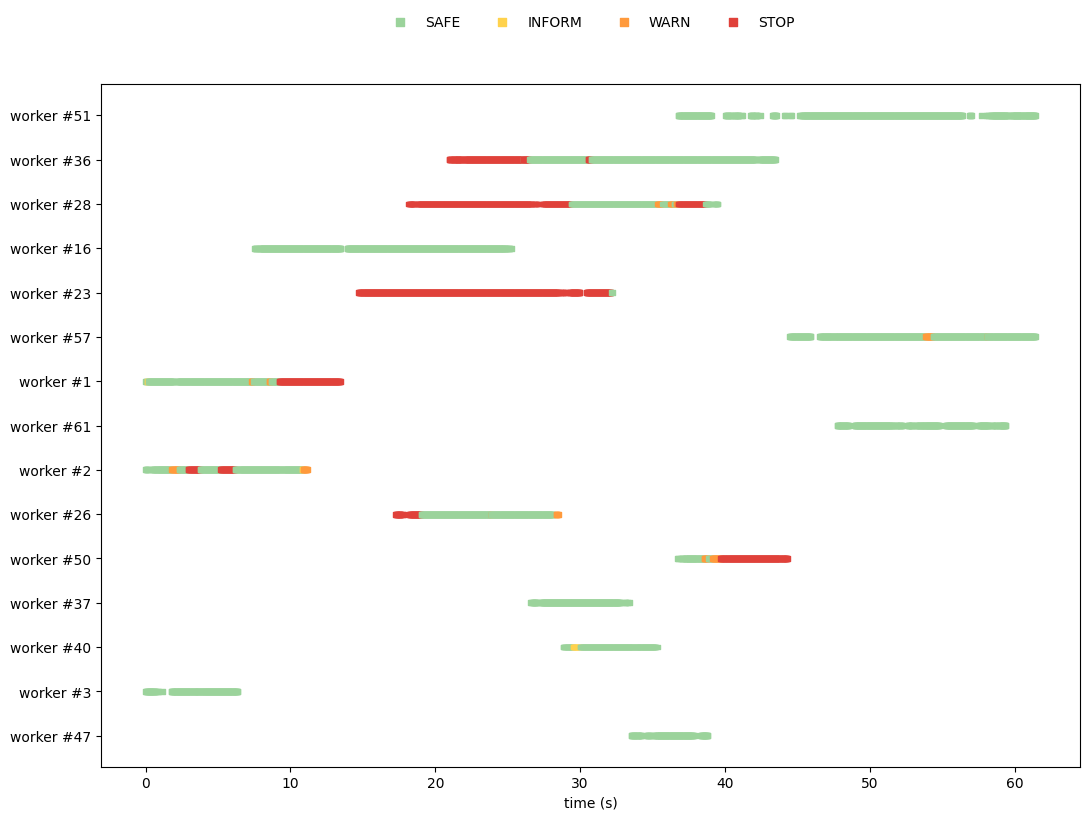

In [17]:
# Timeline: each row is one worker, coloured by warning level over time
top = summary.worker_id.head(15).tolist()
cmap = {"SAFE": "#9bd39b", "INFORM": "#ffd24d", "WARN": "#ff9a3c", "STOP": "#e0413a"}
fig, ax = plt.subplots(figsize=(11, 0.45 * len(top) + 1.5))
for row, tid in enumerate(top):
    g = df[df.worker_id == tid]
    ax.scatter(g.time_s, [row] * len(g), c=g['level'].map(cmap), s=12, marker="s")
ax.set_yticks(range(len(top))); ax.set_yticklabels([f"worker #{t}" for t in top])
ax.set_xlabel("time (s)"); ax.invert_yaxis()
for lv, c in cmap.items():
    ax.scatter([], [], c=c, marker="s", label=lv)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.12), frameon=False)
plt.tight_layout(); plt.savefig("results/warning_timeline.png", dpi=150); plt.show()

## 7. Save results for GitHub

This also makes `demo.gif`, a short low-resolution clip that GitHub can show directly in your README.

Download `results.zip` from the Output panel (refresh it first). GitHub's upload limit is 25 MB per file. If `tracked_output.mp4` is larger, leave it out; the GIF is enough for the README.

In [18]:
import shutil
from PIL import Image
shutil.copy("zone_preview.jpg", "results/")

# A short GIF for the README (GitHub shows GIFs inline; MP4 files are only downloadable)
cap = cv2.VideoCapture(OUT_VIDEO); frames = []; k = 0
step = max(1, int(FPS // 8))                      # about 8 frames per second
while len(frames) < 80:                           # at most about 10 s
    ok, f = cap.read()
    if not ok: break
    if k % step == 0:
        f = cv2.resize(f, (480, int(480 * H / W)))
        frames.append(Image.fromarray(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)))
    k += 1
cap.release()
frames[0].save("results/demo.gif", save_all=True, append_images=frames[1:], duration=125, loop=0)

shutil.make_archive("results", "zip", "results")
for f in sorted(os.listdir("results")):
    print(f"{f:32s} {os.path.getsize(os.path.join('results', f)) / 1e6:6.2f} MB")

demo.gif                           8.48 MB
example_stop_frame.jpg             0.21 MB
example_warning_frame.jpg          0.21 MB
track_log.csv                      0.26 MB
tracked_output.mp4                28.61 MB
warning_timeline.png               0.08 MB
worker_summary.csv                 0.00 MB
zone_preview.jpg                   0.21 MB
